# House Price Prediction Using Machine Learning
**A Case Study of the Melbourne Housing Market**

Dataset: Melbouurne Housing Market

Dataset Source: OpenML

## 1. Business Understanding

### 1.1 Business Problem

Residential real estate prices are influenced by a variety of factors, including location, property size, and proximity to the city center. Understanding how these factors relate to propetry value helps buyers, sellers and real estate professionals make more informed decisions.

This project explores the application of machine learning techniques to predict residential real estate prices in Melbourne, Australia, based on available data on the housing stock.

### 1.2 Project Objectives

Examine dataset and identify significant property features.

Analyze missing value, data quality issues, and relationships between variables.

Develop a linear regression model to serve as a baseline solution.

Develop a random forest regressor model and compare its performance against the baseline model.

Evaluate prediction accuracy and discuss the strengths and limitations of the models used.

### 1.3 Research Question

How accurately can residential real estate prices be predicted using property characteristics and does random forest regression method outperform linear regression?

### 1.4 Modelling Approach

Linear Regression: a baseline model that estimates house prices using linear relationships between input features and the target variable.

Random Forest Regressor: an ensemble learning method that combines multiple decision trees and can capture nonlinear relationships.

The target cariable will be Price.

### 1.5 Success Criteria

The project will be considered successful if:
- both models are capable of generating predictions for new real estate property records.
- a comparison has been made to determine which model yields the best results on the selected test data.

Model performance will be evaluated against a baselinee and interpreted within the context of this specific dataset.

### 1.6 Limitations

The dataset represents historical property transactions and may not reflect current market conditions.

Missing values, incomplete propetry infomation and changes in the housing market may affect prediction accuracy.

## 2. Data Understanding
### 2.1 Dataset Loading

The dataset was obtained from OpenML and converted from ARFF to CSV format. The conversion process is documented in phase 3

In [3]:
import pandas as pd
df = pd.read_csv('/content/melbourne_housing.csv')
print ("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (13580, 21)


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


### 2.2 Dataset Structure
The dataset contains 13,580 records and 21 columns, including Price.

The attributes describe property characteristics, locationsale information. Missing values are also visible in some attributes, like BuildingArea and YearBuilt.

The next step is to examine list of variables, their data types and the number of non-null values.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  object 
 1   Address        13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  object 
 6   SellerG        13580 non-null  object 
 7   Date           13580 non-null  object 
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  object 
 17  Lattitude      13580 non-null  float64
 18  Longti

### 2.3 Missing Values Analysis

The dataset contains 13 numerical variables and 8 variables stored as objects.

Identifiedmissing data in 4 columns: BuildingArea, YearBuilt, CouncilArea and Car.

The largest proportion of missing values occurs in BuildingArea and YearBuilt. This is an important data quality issue because removing all incomplete records could substantially reduce dataset.


In [5]:
missing_values = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum()/len(df)*100).round(2)
})
missing_values[missing_values['Missing Count']>0].sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Count,Missing Percentage
BuildingArea,6450,47.50
YearBuilt,5375,39.58
CouncilArea,1369,10.08
Car,62,0.46


### 2.4 Descriptive Statistics

The analysis includes calculating the mean, standart deviation, minimum, maximum and quartiles for each numerical features.

Particular attention is paid to targetg variable - Price - as well as to property characteristics such as number of rooms, number of bathrooms, distance, building area.

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Rooms,13580.0,2.937997e+00,0.955748,1.00000,2.000000,3.000000,3.000000e+00,1.000000e+01
Price,13580.0,1.075684e+06,639310.724296,85000.00000,650000.000000,903000.000000,1.330000e+06,9.000000e+06
Distance,13580.0,1.013778e+01,5.868725,0.00000,6.100000,9.200000,1.300000e+01,4.810000e+01
Postcode,13580.0,3.105302e+03,90.676964,3000.00000,3044.000000,3084.000000,3.148000e+03,3.977000e+03
Bedroom2,13580.0,2.914728e+00,0.965921,0.00000,2.000000,3.000000,3.000000e+00,2.000000e+01
Bathroom,13580.0,1.534242e+00,0.691712,0.00000,1.000000,1.000000,2.000000e+00,8.000000e+00
Car,13518.0,1.610075e+00,0.962634,0.00000,1.000000,2.000000,2.000000e+00,1.000000e+01
Landsize,13580.0,5.584161e+02,3990.669241,0.00000,177.000000,440.000000,6.510000e+02,4.330140e+05
BuildingArea,7130.0,1.519676e+02,541.014538,0.00000,93.000000,126.000000,1.740000e+02,4.451500e+04
YearBuilt,8205.0,1.964684e+03,37.273762,1196.00000,1940.000000,1970.000000,1.999000e+03,2.018000e+03


Statistics reveal a spread in residential property prices.

Mean price is approximately 1.076 million dollars, while the median - 903,000.

The median numbers of rooms is 3 and median distance to the city center is 9.2 km.

Several variables contain potentially anomalous values. The land size reaches 433,014 m², whereas the median value is 440 m². The maximum building area is 44,515 m² compared to median value of 126m².

Minimum recorded value for the year built is 1196, which may indicate issues with data quality.



### 2.5 Price Distribution


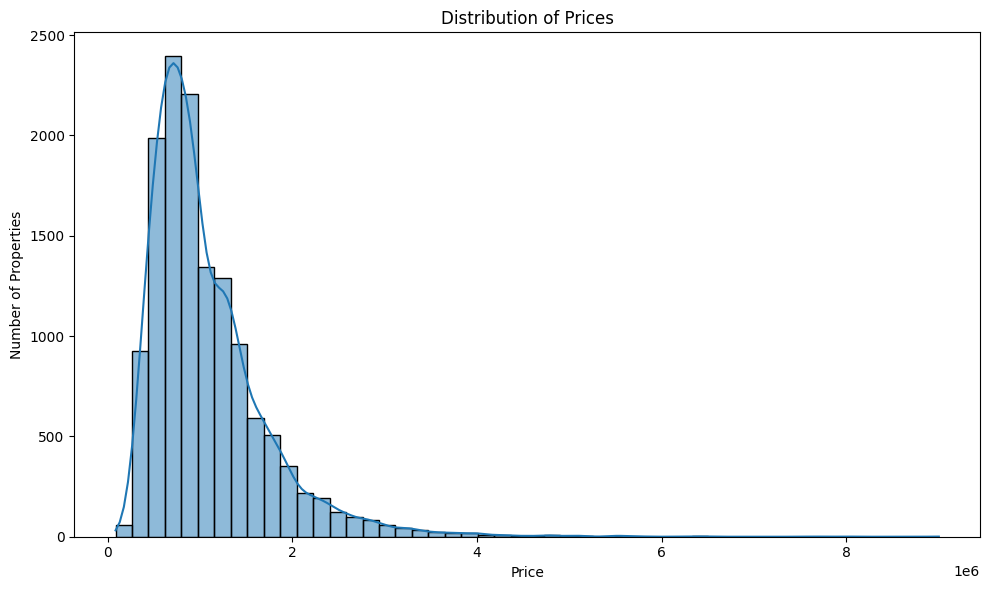

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.histplot(df['Price'], bins=50, kde=True)
plt.title('Distribution of Prices')
plt.xlabel('Price')
plt.ylabel('Number of Properties')
plt.tight_layout()
plt.show()

**Interpretation of Price Distribution**

The most properties concentrated in the lower and middle price range. A long right tail indicates that a relatively small number of properties have substantially higher price.

### 2.6 Relationship Between Rooms and Price

A barplot is used to compare price distributions across different room counts and to identify varibility and potential outliers within each group.

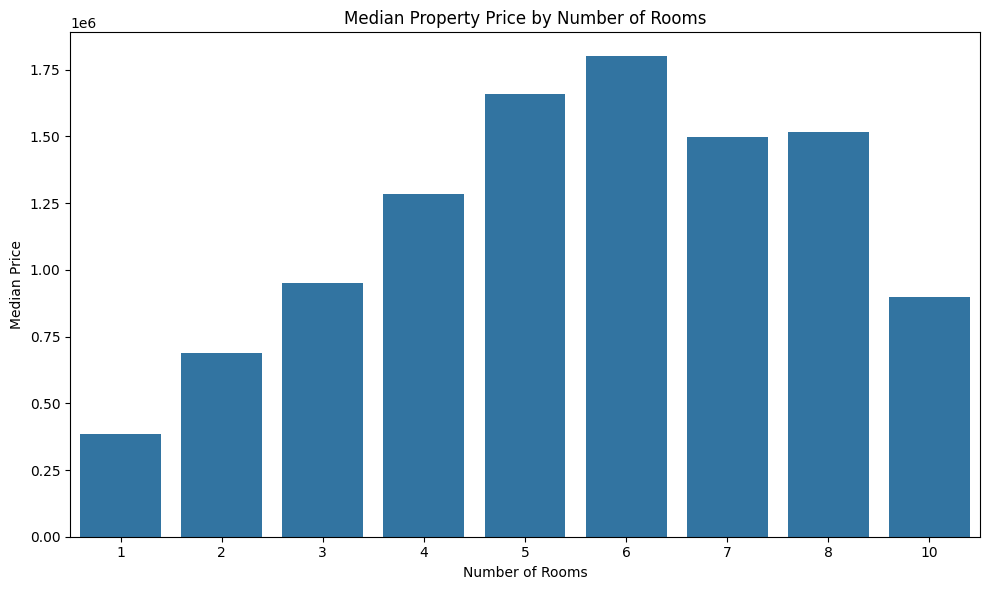

In [8]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=df,
    x='Rooms',
    y='Price',
    estimator='median',
    errorbar=None
)
plt.title('Median Property Price by Number of Rooms')
plt.xlabel('Number of Rooms')
plt.ylabel('Median Price')
plt.tight_layout()
plt.show()

The bar chart shows a general increase in median property prices as the number of rooms increases, particularly for properties with 1 to 6 rooms.The relationship is not stricly linear. Properties with 7, 8, and 10 rooms have lower median prices those with six rooms.

This variation may be influenced by differences in property location, type and the number of observations within each room category.

Overall, the results suggest that the rooms may be useful predictor of property prices.

### 2.7 Check the number of objects

In [9]:
room_counts=df['Rooms'].value_counts().sort_index()
display(room_counts)

,count
Rooms,
1,681
2,3648
3,5881
4,2688
5,596
6,67
7,10
8,8
10,1


The majority of real estate properties have between 2 and 4 rooms. The most common category consists of properties with 3 rooms (5,881).

The median price for properties with 10 rooms is based on a single observation and cannot be considered representative.

### 2.8 Relationship between Distance and Price

A scatterplot is used to investigate whether properties located father from the city center tend to have lower prices.

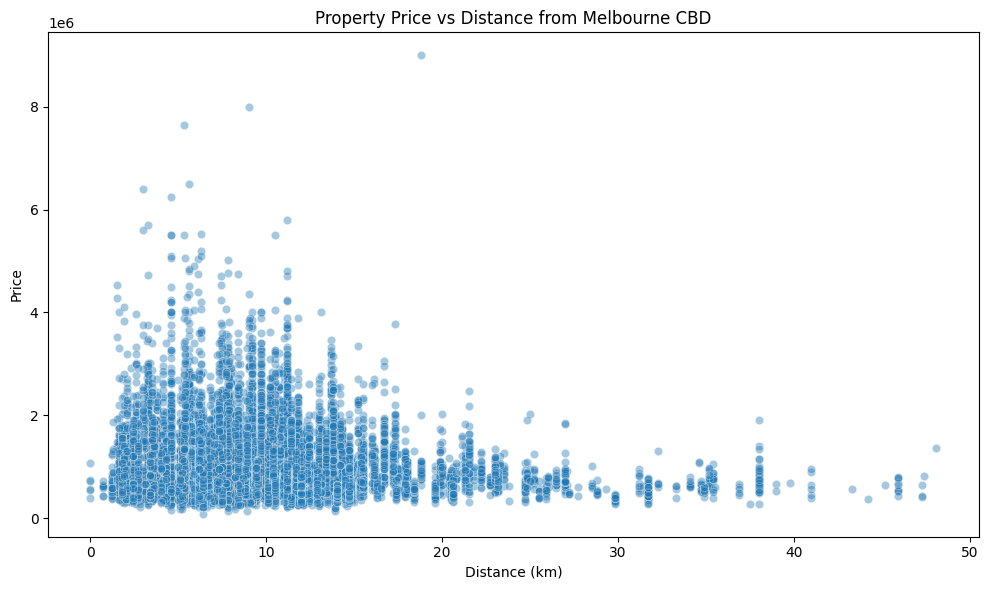

In [10]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df,
    x='Distance',
    y='Price',
    alpha=0.4
)
plt.title('Property Price vs Distance from Melbourne CBD')
plt.xlabel('Distance (km)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

Higher-priced properties are more frequently observed within approximately 5-15km of the city centre. As distance increases, the upper range of property prices generally decreases.

Several high-priced outliers are also visible, including a property valued at approximately 9 million around 18 km from Central Business District.

### 2.9 Correlation Analysis

Pearson correlation coefficiets are calculated to investigate linear relationships between numerical property characteristics and the target variable, Price.

In [11]:
numeric_df= df.select_dtypes(include='number')
price_correlations = (
    numeric_df.corr()['Price']
    .sort_values(ascending=False)
)
display(price_correlations)

,Price
Price,1.000000
Rooms,0.496634
Bedroom2,0.475951
Bathroom,0.467038
Car,0.238979
Longtitude,0.203656
Postcode,0.107867
BuildingArea,0.090981
Landsize,0.037507
Propertycount,-0.042153


**Interpretation of Correlation Analysis**

The correlation analysis indicates that Rooms (r=0.497), Bedroom2 (r=0.476), and Bathroom (r=0.467) have the strongest positive linear relationships with property prices among the numerical variables.

Distance has a weak negative correlation with Price (r=-0.163), suggesting that properties father from centre tend to have somewhat lower prices, although the relationship is not strong.

YearBuilt shows a moderate negative correlation (r=-0.324). However, this result should be interpreted cautiously because variable contains many missing values and potentially invalid observations.

Landsize (r=0.038) and BuildingArea (r=0.091) show weak linear relationships with price. This does not necessarily mean these features are unimportant, as nonlinear relationships and outliers may affect the results.

Overall, the analysis suggests that property characteristics and location may contribute to price prediction.

### 2.10 Data Quality Assesment

Before preparing dataset for modelling, additional dataquality checks are performed to identify duplicate records, potentially invalid values.

Particular attention is given to variables where descriptive statistics revealed unusual observations, including YearBuilt, BuildingArea, Landsize.

In [12]:
print("Duplicate rows:", df.duplicated().sum())
print("YearBuilt before 1800:", (df['YearBuilt']<1800).sum())
print("BuildingArea equal to zero:", (df['BuildingArea'] == 0).sum())
print("Landsize equal to zero:", (df['Landsize'] == 0).sum())
print("Bathroom equal to zero:", (df['Bathroom'] ==0).sum())

Duplicate rows: 0
YearBuilt before 1800: 1
BuildingArea equal to zero: 17
Landsize equal to zero: 1939
Bathroom equal to zero: 34


In [13]:
# Investigate zero land size by property type
pd.crosstab(
    df['Type'],
    df['Landsize'] == 0,
    rownames=['Property Type'],
    colnames=['Landsize is Zero']
)

Landsize is Zero,False,True
Property Type,,
h,9278,171
t,975,139
u,1388,1629


**Investigation of Zero Land Size Values**

The cross-tabulation shows that zero values in Landsize are strongly associated with property type.

Among properties classified as units (u) 1,629 out of 3,017 observations have a recorded land size of zero.

In comparison, zero land size is recorded for approximatly 12.5% of townhouses (t) and only 1.8% of houses (h).

The pattern suggests that zero land size may reflect differences in how land area is recorded for different property types, rather than necessarily indicating invalid data.

## 3. Data Preparation
### 3.1 Dataset Format Conversion (ARFF to CSV)

The original dataset was downloaded from OpenML in ARFF format.
The dataset was converted to CSV format using Python and the liac-arff and pandas libraries.

References: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html

In [14]:
%pip install liac-arff

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for liac-arff: filename=liac_arff-2.5.0-py3-none-any.whl size=11772 sha256=2d7a59ad819595bc405ba2d3ca35c387cee5a5360fe810746ea90320febe8f8c
  Stored in directory: /root/.cache/pip/wheels/93/f3/5b/658a9bddee916a5f4b84bdc1a4e0fabd22fb17947c2c9542e6
Successfully built liac-arff


In [15]:
from ast import Attribute
import arff
import pandas as pd

with open('/content/dataset_', 'r', encoding='utf-8') as file:
    dataset = arff.load(file)

columns = [attribute[0] for attribute in dataset['attributes']]
df = pd.DataFrame(dataset['data'], columns=columns)

df.to_csv('/content/melbourne_housing.csv', index=False)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (13580, 21)


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


### 3.2 Data Cleaning

Cleaning decisions will be based on the results of the exploratory analysis. In particular, zero values in Landsize will not be automatically removed because they are common among properties classified as units.

Missing values and potentially invalid observations will be investigated before deciding how to handle them.

In [16]:
df_raw = pd.read_csv('/content/melbourne_housing.csv')
df_clean = df_raw.copy()
print("Original dataset shape:", df_raw.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (13580, 21)
Working dataset shape: (13580, 21)


### 3.3 Investigation of Potentially Invalid Values

The descriptive statistics revealed potentially unusual values in YearBuilt, BuildingArea, Bathroom.

It is necessary to determine whether these values are the results of data entry errors, missing information, or are in fact, valid observations.

In [17]:
print("Properties built before 1800:")
display(
    df_clean.loc[
        df_clean['YearBuilt']<1800,
        ['Suburb', 'Type', 'Price', 'YearBuilt']
    ]
)

print("Properties with zero building area:")
display(
    df_clean.loc[
        df_clean['BuildingArea'] == 0,
        ['Suburb', 'Type', 'BuildingArea']
    ].head(10)
)

print("Properties with zero bathrooms:")
display(
    df_clean.loc[
        df_clean['Bathroom'] == 0,
        ['Suburb', 'Type', 'Rooms', 'Bathroom']
    ].head(10)
)

Properties built before 1800:


,Suburb,Type,Price,YearBuilt
9968,Mount Waverley,h,1200000.0,1196.0


Properties with zero building area:


,Suburb,Type,BuildingArea
4344,North Melbourne,t,0.0
12226,Balwyn North,h,0.0
12249,Bundoora,h,0.0
12395,Roxburgh Park,h,0.0
12412,Thornbury,t,0.0
13040,Prahran,h,0.0
13207,Huntingdale,h,0.0
13348,Balwyn North,h,0.0
13370,Brighton East,h,0.0
13380,Bundoora,h,0.0


Properties with zero bathrooms:


,Suburb,Type,Rooms,Bathroom
139,Alphington,h,3,0.0
281,Armadale,u,2,0.0
505,Balaclava,u,2,0.0
584,Balwyn,h,2,0.0
913,Bentleigh East,h,3,0.0
1063,Brighton,h,3,0.0
1070,Brighton,t,3,0.0
1593,Camberwell,h,4,0.0
2253,Elsternwick,u,2,0.0
2777,Glen Iris,h,2,0.0


### 3.4 Handing Potentially Invalid Values

The TearBuilt value of 1196 was considered implausible and replaced with NaN.
Zero values in BuildingArea, Bathroom were treated as potentially missing measurements and replaced with NaN. This decision assumes that these zero values do not represent valid measurements for the intended prediction task.

In [18]:
import numpy as np
df_clean = df_raw.copy()
df_clean.loc[df_clean['YearBuilt']<1800, 'YearBuilt']=np.nan
df_clean.loc[df_clean['BuildingArea'] == 0, 'BuildingArea']=np.nan
df_clean.loc[df_clean['Bathroom'] == 0, 'Bathroom']=np.nan

comparison=pd.DataFrame({
    'Before cleaning': df_raw.isna().sum(),
    'After Cleaning': df_clean.isna().sum()
})

display(comparison[comparison['After Cleaning']>0])
print("Original shape:", df_raw.shape)
print("Cleaned shape:", df_clean.shape)

,Before cleaning,After Cleaning
Bathroom,0,34
Car,62,62
BuildingArea,6450,6467
YearBuilt,5375,5376
CouncilArea,1369,1369


Original shape: (13580, 21)
Cleaned shape: (13580, 21)


### 3.5 Data Preparation Log

The initial cleaning stage converted selected potentially invalid values to missing values without removing any property records.

| Issue | Action | Records Affected | Rationale |
|---|---|---|---|
| YearBuilt < 1800 | Replaced with NaN | 1 | Implausible construction year |
| BuildingArea = 0 | Replaced with NaN | 17 | Potentially missing measurement |
| Bathroom = 0 | Replaced with NaN | 34 | Potentially invalid bathroom count |
| Landsize = 0 | Retained | 1939 | Common among units |

### 3.6 Feature Selection

The target variable is Price. Candidate predictors include property size, room counts, location, property type, and other available characteristics.

In [19]:
feature_summary = pd.DataFrame({
    'Data Type': df_clean.dtypes,
    'Unique Values': df_clean.nunique(),
    'Missing Values': df_clean.isna().sum()
})
display(feature_summary)

,Data Type,Unique Values,Missing Values
Suburb,object,314,0
Address,object,13378,0
Rooms,int64,9,0
Type,object,3,0
Price,float64,2204,0
Method,object,5,0
SellerG,object,268,0
Date,object,58,0
Distance,float64,202,0
Postcode,float64,198,0


Based on the exploratory analysis and feature summary, 12 predictor variables were selected for the initial modelling experiment.

Numerical features: Rooms, Bedroom2, Bathroom, Car, Distance, Landsize, BuildingArea, YearBuilt, Lattitude, Longtitude.

Categorical features: Type, Regionname.

The Address variable was excluded because it contains nearly unique values for individual properties. High-cardinality categorical variables such as Suburn, SellerG were excluded from initial experiment to reduce preprocessing complexity.

In [20]:
numerical_features = [
    'Rooms', 'Bedroom2', 'Bathroom', 'Car',
    'Distance', 'Landsize', 'BuildingArea',
    'YearBuilt', 'Lattitude', 'Longtitude'
]
categorical_feature = [
    'Type', 'Regionname'
]
X=df_clean[numerical_features + categorical_feature]
y=df_clean['Price']
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Selected features:", X.columns.tolist())

Features shape: (13580, 12)
Target shape: (13580,)
Selected features: ['Rooms', 'Bedroom2', 'Bathroom', 'Car', 'Distance', 'Landsize', 'BuildingArea', 'YearBuilt', 'Lattitude', 'Longtitude', 'Type', 'Regionname']


### 3.7 Train/Test Split

The dataset was divided into training and testing subsets using 80/20 split.

A fixed random state of 42 was used to make the split reproducible.

Missing-value imputation and categorical encoding will be fitted only on the training data through a preprocessing pipeline. This approach helps prevent data leakage from the test set.

Both Linear Regression and Random Forest Regressor will use the same trainig and testing subsets.

In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state=42
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (10864, 12)
X_test: (2716, 12)
y_train: (10864,)
y_test: (2716,)


### 3.8 Preprocessing Pipeline

For numerical features, missing values will be replaced using the median, followed by standardisation using StandardScaler.

For categorial features, missing values will be replaced with the most frequent category, followed by one-hot encoding.

ColumnTransformer combines these transformations into a single preprocessing workflow.

The proprocessing steps will be fitted on the training data only and subsequently applied to test data. This prevents information from test set from influencing the preprocessing parameters.

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_feature)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


### 3.9 Check Preprocessing Pipeline

In [23]:
import numpy as np
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)
print("Prepared training shape:", X_train_prepared.shape)
print("Prepared testing shape:", X_test_prepared.shape)
print("Missing values in training data:",
      np.isnan(X_train_prepared).sum())
print("Missing values in testing data:",
      np.isnan(X_test_prepared).sum())

Prepared training shape: (10864, 21)
Prepared testing shape: (2716, 21)
Missing values in training data: 0
Missing values in testing data: 0


### 3.10 Preprocessing Validation

The original 12 predictors were expanded to 21 features through one-hot encoding of the categorical variables Type and Regionname.

Validation confirmed that no missing values remained in either transformed dataset.

## 4. Modelling
### 4.1 Linear Regression - Baseline Model

Linear Regression provides an interpretable starting point against which the performance of a more flexible Random Forest Regressor can be compared.

A scikit-learn Pipeline is used to combine preprocessing and model training.

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone

linear_model = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('regressor', LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression model training successfully!")

Linear Regression model training successfully!


### 4.2 Linear Regression Evaluation

The trained Linear Regression model was evaluated using the held-out test dataset.

Three regression metrics were selected:
- Mean Absolute Error: The average absolute difference between actual and predicted property prices, measured in Australia dollars.
- Root Mean Squared Error: A measure of prediction error that gives greater weight to large errors, also measured in Australia dollars.
- R² Score: The proportion of variation in property prices explained by the model on the test dataset.

Lower MAE and RMSE values indicate better predictive accuracy, while R² values indicate better explanatory performance.

The same metrics will be used to evaluate Random Forest Regressor, allowing a direct comparison between the two models.

In [25]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_linear = linear_model.predict(X_test)
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))
linear_r2 = r2_score(y_test, y_pred_linear)

print(f"Linear Regression MAE: AUD {linear_mae:,.2f}")
print(f"Linear Regression RMSE: AUD {linear_rmse:,.2f}")
print(f"Linear Regression R²: {linear_r2:.4f}")


Linear Regression MAE: AUD 268,253.47
Linear Regression RMSE: AUD 394,364.20
Linear Regression R²: 0.6085


**Linear Regression Results and Interpretation**

The Mean Absolute Error indicates that the model`s predictions differ from actual property prices by approximately 268,253 on average.

The RMSE is higher (394,364.20) than the MAE, suggesting that some predictions have relatively large errors. This may be influenced by the wide variation in Melbiurne property prices, including high-value properties identified during exploratory data analysis.

The R² score of 0.6085 indicates that the model explains approximately 60.85% of the variation in property prices within the test dataset.

Although Linear Regression captures a substantial proportion of price variation, its prediction errors remain considerable.





### 4.3 Random Forest Regressor

Random Forest combines predictions from multiple decision trees and can capture nonlinear relationships and interactions between property characteristics.

An initial configuration of 100 decision trees and a fixed random state of 42 will be used. Model performance will be assessed using MAE, RMSE, R².

In [26]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
rf_model = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('regressor', RandomForestRegressor(
        n_estimators = 100,
        random_state = 42,
        n_jobs = -1
    ))
])

rf_model.fit(X_train, y_train)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


### 4.4 Random Forest Evaluation

The trained Random Forest Regressor was evaluated on the same held-out test dataset used for Linear Regression.

In [27]:
y_pred_rf = rf_model.predict(X_test)
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2 = r2_score(y_test, y_pred_rf)

print(f"Random Forest MAE: AUD {rf_mae:,.2f}")
print(f"Random Forest RMSE: AUD {rf_rmse:,.2f}")
print(f"Random Forest R²: AUD {rf_r2:.4f}")

Random Forest MAE: AUD 165,914.63
Random Forest RMSE: AUD 273,559.09
Random Forest R²: AUD 0.8116


### 4.5 Model Comparison

The performance of Linear Regression and Random Forest Regressor was compared using the same held-out test dataset.

| Evaluation Metric | Linear Regression | Random Forest Regressor|
|---|---|---|
| MAE | 268,253.47 | 165,914.63 |
| RMSE | 394,364.20 | 273,559.09 |
| R² | 0.6085 | 0.8116 |

Random Forest Regressor outperformed Linear Regression across all three evaluation metrics.

However, the Random Forest model still has an average absolute prediction error of approximately 165,915. Therefore, its predictions should not be interpreted as precise property valuations.

The results support the research hypothesis that Random Forest Regressor can achive better predictive performance that the Linear Regression baseline on this dataset and test split.



In [28]:
comparison_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [linear_mae, rf_mae],
    'RMSE': [linear_rmse, rf_rmse],
    'R²': [linear_r2, rf_r2]
})

display(comparison_df.round(2))

,Model,MAE,RMSE,R²
0,Linear Regression,268253.47,394364.20,0.61
1,Random Forest,165914.63,273559.09,0.81


### 4.6 Actual vs Predicted Prices

Scatter plots were used to compare actual property prices with the predictions generated by Linear Regression and Random Forest Regressor.

A diagonal reference line represents perfect predictions, where predicted prices equal actual prices.

Points closer to this line indicate more accurate predictions, while points further away indicate larger prediction errors.

These visualisations provide an additional comparisonof model performance beyond MAE, RMSE, R².

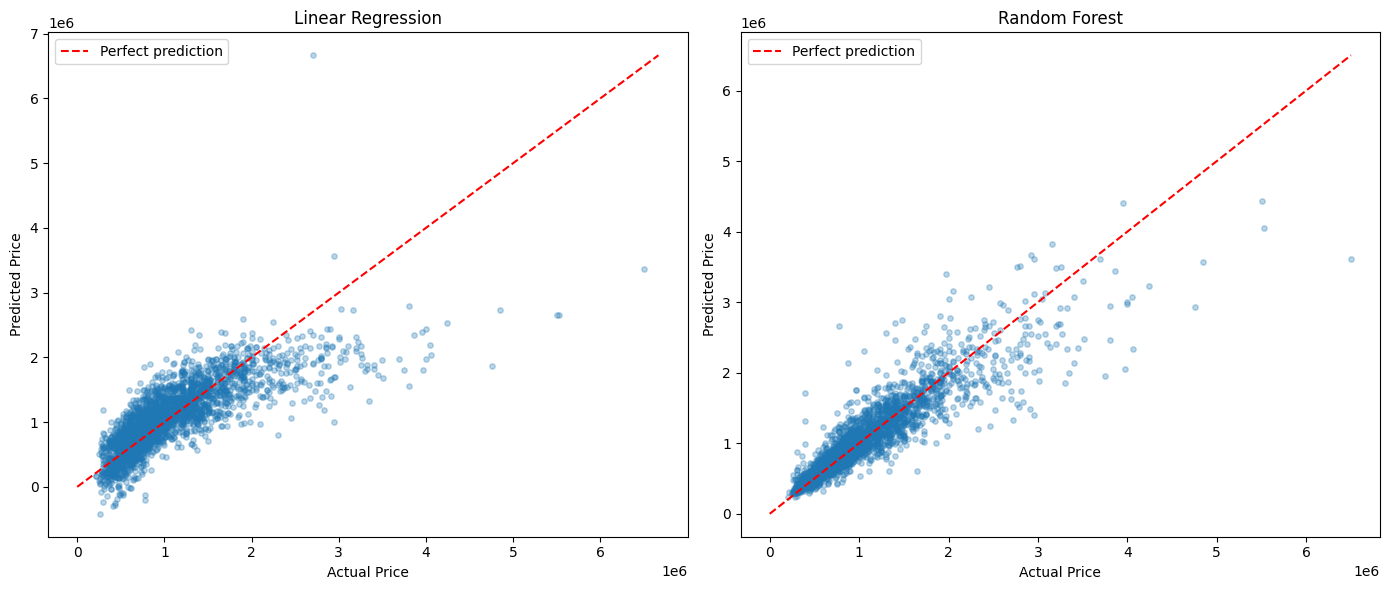

In [30]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1,2,figsize=(14,6))
models=[
    ("Linear Regression", y_pred_linear),
    ("Random Forest", y_pred_rf)
]

for ax, (name, predictions) in zip(axes, models):
  ax.scatter(y_test, predictions, alpha=0.3, s=15)
  max_price = max(y_test.max(), predictions.max())
  ax.plot(
      [0,max_price],
      [0,max_price],
      'r--',
      label='Perfect prediction'
  )

  ax.set_title(name)
  ax.set_xlabel("Actual Price")
  ax.set_ylabel("Predicted Price")
  ax.legend()

plt.tight_layout()
plt.show()

The results suggest that Random Forest captures more complex relationship between property characteristics and prices than Linear Regression, but neither model provides consistently accurate predictions across the entite price range.

### 4.7 Overfitting Check

To access potential overfitting, the performance of Raandom Forest Regressor will be compared between the training and test datasets.

In [31]:
rf_train_pred = rf_model.predict(X_train)
rf_test_pred = rf_model.predict(X_test)

overfitting_check = pd.DataFrame({
    'Dataset': ['Training', 'Testing'],
    'MAE': [
        mean_absolute_error(y_train, rf_train_pred),
        mean_absolute_error(y_test, rf_test_pred)
    ],
    'R²': [
        r2_score(y_train, rf_train_pred),
        r2_score(y_test, rf_test_pred)
    ]
})

display(overfitting_check.round(4))

,Dataset,MAE,R²
0,Training,62697.9569,0.9701
1,Testing,165914.6251,0.8116


The substantial difference between training and test performance suggests that Random Forest model is overfitting to some extent.

Although the model generalises less effectively to unseen observations that to the training data, it still substantially outperforms the Linear Regression baseline on the test set.

This finding indicates that controlling model complexity may improve generalisation. Potential approaches include limiting tree depth and increasing minimum number of samples required to form leaf nodes.

### 4.8 Random Forest Hyperparameter Turning

To investigate whether limiting model complexity could improve generalisation, a small hyperparameter search was conducted using GridSearchCV.

Two value of max_depth (10and20) and two value of min_samoles_leaf (1and5) were evaluated while n_estimator was fixed at 100.

Three-fold cross-validation was performed using the training dataset only. The selection criterion was Mean Absolute Error, with lower values indicating better performance.

In [42]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import  Pipeline
from sklearn.base import clone

rf_tuning_pipeline = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    'regressor__max_depth': [10, 20],
    'regressor__min_samples_leaf': [1, 5]
}

grid_search = GridSearchCV(
    estimator=rf_tuning_pipeline,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=3,
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print(f"Best CV MAE: {-grid_search.best_score_:,.2f}")

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'regressor__max_depth': 20, 'regressor__min_samples_leaf': 1}
Best CV MAE: 173,365.04


### 4.9 Evaluation of the Tuned Random Forest

GridSearchCV identified max_depth=20 and min_sample_leaf=1 as the best-performing hyperparameter combination among the four candidates.

The best three-fold cross-validation MAE was 173,365.04.

The selected model will now be evaluated on the training and test datasets to examine its generalisation performance and compare it with the original Random Forest model.

In [43]:
tuned_rf_model = grid_search.best_estimator_
tuned_train_pred = tuned_rf_model.predict(X_train)
tuned_test_pred = tuned_rf_model.predict(X_test)
tuning_comparison = pd.DataFrame({
    'Model': ['Original Random Forest', 'Tuned Random Forest'],
    'Train MAE': [
        mean_absolute_error(y_train, rf_train_pred),
        mean_absolute_error(y_train, tuned_train_pred)
    ],
    'Test MAE': [
        r2_score(y_train, rf_train_pred),
        r2_score(y_train, tuned_train_pred)
    ],
    'Test R²': [
        r2_score(y_test, rf_test_pred),
        r2_score(y_test,  tuned_test_pred)
    ]
})

display(tuning_comparison.round(4))

,Model,Train MAE,Test MAE,Test R²
0,Original Random Forest,62697.9569,0.9701,0.8116
1,Tuned Random Forest,65982.9504,0.9688,0.8125


The results suggest that limiting tree depth to 20 slightly reduced the model`s fit to the training data without substantially changing its performance on unseen observations.

In [45]:
print("Original RF Test MAE:",
      round(mean_absolute_error(y_test, rf_test_pred), 2))
print("Tuned RF Test MAE:",
      round(mean_absolute_error(y_test, tuned_test_pred), 2))
print("Original RF Test RMSE:",
      round(mean_squared_error(y_test, rf_test_pred) ** 0.5, 2))
print("Tuned RF Test RMSE:",
      round(mean_squared_error(y_test, tuned_test_pred) ** 0.5, 2))

Original RF Test MAE: 165914.63
Tuned RF Test MAE: 165964.13
Original RF Test RMSE: 273559.09
Tuned RF Test RMSE: 272890.14


The original Random Forest achieved the lowest test MAE compared with Linear Regression and the tuned Random Forest.

The tuned Random Forest achieved a slightly lower RMSE and a marginally higher R². However, these differences were very small.

Hyperparameter tuning therefore did not produce a meaningful improvement in predictive performance.

The original Random Forest was retained as the preferred model because it achieved the lowest test MAE.

Nevertheless, the substantial difference between its training and test performance indicates some overfitting. The model should therefore be interpreted as a useful predictive baseline rather than a fully validated property valuation system.

## 5. Evaluation

### 5.1 Evaluation Against Business Objectives

The main research question was: How accurately can residential property prices in Melbourne be predicted using property characteristics, and does aRandom Forest Regression outperform Linear Regression?

The results demonstrate that Random Forest Regression outperformed Linear Regression on the held-out test dataset.

Linear Regression achieved a Mean Absolute Error of 268,253.47, a Root Mean Squared Error of 394,364.20 and R² of 0.6085.

The original Random Forest achieved an MAE of 165,914.63 an RMSE of 273,559.09 and an R² of 0.8116.

This represents an approximately 38.2% redustion in MAE and a 30.6% reduction in RMSE compared with Linear Regression.

The Random Forest model therefore met the comparative objective of improving predictive accuracy over the baseline model.

However, an average absolute prediction error of approximately 166,000 remains substantial. The results indicate that the model can identify useful patterns in Melbourne property prices, but its predictions should not be treated as precise individual valuations.

Hyperparameter tuning produced only marginal changes in the test performance. The original Random Forest was retained as the preferred model based on its slightly lower MAE.

Overall, the research question was answered: Random Forest provided more accurate predictions than Linear Regression for this dataset ans evaluation split, although further validation would be required before practical deployment.

In [46]:
mae_improvement = (
    (linear_mae - rf_mae) / linear_mae
) * 100

rmse_improvement = (
    (linear_rmse - rf_rmse) / linear_rmse
) * 100

print(f"MAE improvement: {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")
print(f"Linear Regression R²: {linear_r2:.4f}")
print(f"Random Forest R²: {rf_r2:.4f}")

MAE improvement: 38.15%
RMSE improvement: 30.63%
Linear Regression R²: 0.6085
Random Forest R²: 0.8116


### 5.2 Model Limitations and Risks

Although Random Forest Regression substantially outperformed Linera regression, several limitations must be considered when interpreting the results.

Missing data: The original dataset contained substantial missing information, particularly for BuildingArea and YearBuilt. Median imputation allowed these observations to be retained, but the imputed values may not accurately represent the original properties. This could reduce predictive accuracy.

Overfitting: The original Random Forewst achived an R² of 0.9701 on the training data and 0.8116 on the test data. This performance gap suggests that the model learned some patterns specific to the training observations that did not generalise fully to unseen properties.

High-value properties: The actual-versus-predicted visualisations showed that the Random Forest tended to underestimate some expensive properties. The model may therefore be less reliable for unusual or luxury homes.

Evaluation strategy: The dataset was divided using random 80/20 train-test split. This approach provides an initial estimate of predictive performance but does not assess how well the model would perform on properties sold in a later time period. Furthermore, the test set was inspected before hyperparameter tuning, so the tuned model`s test results should be considered exploratory.

Practical and ethical risks: The original Random Forest achieved a test MAE of approximately 165,915. Such an error could have significant financial consequences if predictions were used without professional review. The model may also perform differently across property types, locations, and price range, which were not evaluated separately.

Overall, the model demonstrates useful predictive capability, but the results do not establish that it is sufficiently reliable for independent real-world property valuation.

### 5.3 Final Evaluation Decision

Both Linear Regression and Random Forest Regression were successfully implemented and evaluated using the same training and test datasets. Random Forest achived substantially better predictive performance, reducing test MAE by 38.15% and RMSE by 30.63% compare with LInear Regression.

The original Random Forest was selected as the preffered model because it achived the lowest test MAE of AUD 165,914.63 and R² of 0.8116. Hyperparameter tuning produced only marginal differences in predictive performance.

However, the model is not considered ready for independent real-world deployment. The prediction errors remain financially significant, the model shows evidence of overfitting, and its performance has not been validated on a separate time period or across different property market segments.

Before practical use, further work would be required, including temporal validations, investigation of missing data, evaluation across property types and price ranges, and monitoring of prediction errors.

The project successfully answered its research question and demonstrated the value of Random Forest Regression for predicting Melbourne house prices.